# 05 · Vanilla GAN (MLP / Fully-Connected)

**Generator:** z (100) → 256 → 512 → 1024 → 784 (Tanh), LeakyReLU(0.2)
**Discriminator:** x (784) → 512 → 256 → 1 (logit), LeakyReLU(0.2)
Sengaja **tanpa** BatchNorm dan **tanpa** konvolusi, supaya perbedaannya dengan DCGAN terlihat jelas.

**Loss (adversarial):**
- Discriminator: L_D = −𝔼[log D(x)] − 𝔼[log(1 − D(G(z)))]
- Generator (non-saturating): L_G = −𝔼[log D(G(z))]
- Kalau D optimal, permainan minimax ini setara dengan meminimalkan **divergensi Jensen–Shannon** D_JS(P_data ‖ P_g).

> **Ide utama (loss → visual):**
> GAN **tidak menghitung selisih per piksel**. Generator hanya dinilai dari "apakah gambarnya bisa menipu Discriminator". Gambar buram mudah ketahuan palsu, jadi generator terdorong membuat **tepi dan tekstur yang tajam**.
> Kelemahannya, ini adalah **permainan dua pemain** (minimax), bukan sekadar meminimalkan satu loss. Akibatnya loss bisa **naik-turun terus (osilasi)**. Generator juga bisa "curang" dengan hanya membuat beberapa jenis gambar yang paling ampuh menipu D (***mode collapse***).
> Pada awal training, D dengan mudah menolak gambar palsu (D(G(z)) ≈ 0). Pada titik itu, loss asli log(1 − D(G(z))) hampir datar, sehingga gradiennya hampir nol (***vanishing gradient***). Karena itu dipakai bentuk *non-saturating*. Bagian 8 mengukur hal ini secara langsung.

In [1]:
%run ./00_helpers.ipynb

device = cuda | dataset = fashion_mnist | QUICK = False
folder proyek = c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN
hasil -> c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results
Helpers siap ✔


c:\Users\Derry\Anaconda\envs\deep-learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Dataset

In [2]:
set_seed()
splits = load_splits()
loaders = make_loaders(splits)
x_test, y_test = splits["test"]

Jumlah data: {'train': 56000, 'val': 7000, 'test': 7000}


## 2. Hyperparameter

In [3]:
Z_DIM = 100
MAX_EPOCHS = n_epochs(100)
LEARNING_RATE = 2e-4
BETAS = (0.5, 0.999)

## 3. Model

In [4]:
class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.z_dim = z_dim
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2),
            nn.Linear(1024, IMG_SIZE), nn.Tanh())

    def forward(self, z):
        return self.net(z).view(-1, *IMG_SHAPE)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(IMG_SIZE, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1))

    def forward(self, x):
        return self.net(x.flatten(1)).squeeze(1)     # logit (belum di-sigmoid)


G = Generator(Z_DIM).to(device)
D = Discriminator().to(device)

opt_G = torch.optim.Adam(G.parameters(), lr=LEARNING_RATE, betas=BETAS)
opt_D = torch.optim.Adam(D.parameters(), lr=LEARNING_RATE, betas=BETAS)
print(G); print(D)
print("Parameter G:", count_params(G), "| D:", count_params(D))

Generator(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)
Parameter G: 1486352 | D: 533505


## 4. Loss Function

`BCEWithLogits` = sigmoid + binary cross-entropy dalam satu langkah, sehingga lebih stabil secara numerik.
- `d_loss`: D belajar memberi nilai 1 untuk gambar asli dan 0 untuk gambar buatan Generator (`x_gen`).
- `g_loss_nonsat`: G belajar membuat D memberi nilai **1** untuk gambar buatannya → −log D(G(z)).
- `g_loss_sat`: bentuk minimax asli log(1 − D(G(z))). **Hanya dipakai untuk diagnosis** vanishing gradient, bukan untuk training.

In [5]:
bce = nn.BCEWithLogitsLoss()

def d_loss_fn(real_logits, gen_logits):
    return bce(real_logits, torch.ones_like(real_logits)) + bce(gen_logits, torch.zeros_like(gen_logits))

def g_loss_nonsat(gen_logits):
    return bce(gen_logits, torch.ones_like(gen_logits))            # -log D(G(z))

def g_loss_sat(gen_logits):
    return -bce(gen_logits, torch.zeros_like(gen_logits))          # log(1 - D(G(z)))

def grad_norm(params):
    return sum(p.grad.detach().pow(2).sum().item() for p in params if p.grad is not None) ** 0.5

def gradient_diagnostic(z):
    # Q3: besar gradien G untuk loss saturating vs non-saturating pada batch z yang sama (tanpa update bobot)
    out = {}
    for kind, fn in [("saturating", g_loss_sat), ("non_saturating", g_loss_nonsat)]:
        G.zero_grad(set_to_none=True)
        fn(D(G(z))).backward()
        out[kind] = grad_norm(G.parameters())
    G.zero_grad(set_to_none=True); D.zero_grad(set_to_none=True)
    return out

## 5. Training

Setiap iterasi:
1. **Update D:** maksimalkan log D(x) + log(1 − D(G(z))).
2. **Update G:** minimalkan −log D(G(z)).

Yang dicatat: loss D & G per iterasi, rata-rata D(x) dan D(G(z)) per epoch (0.5 = keseimbangan ideal), diagnosis gradien, dan *snapshot* gambar dari z yang sama di beberapa epoch (untuk melihat mode collapse).

In [6]:
g = torch.Generator(device=device).manual_seed(SEED)
fixed_z = torch.randn(16, Z_DIM, device=device, generator=g)
diag_z = torch.randn(256, Z_DIM, device=device, generator=g)

history = {"model": "gan", "params": count_params(G) + count_params(D), "params_G": count_params(G),
           "epoch": [], "epoch_time_s": [], "iter_d_loss": [], "iter_g_loss": [], "train": [],
           "grad_diag": [], "snapshots": {}}

for epoch in range(1, MAX_EPOCHS + 1):
    G.train(); D.train()
    t0 = time.perf_counter()
    s = {"d_loss": 0.0, "g_loss": 0.0, "D_x": 0.0, "D_G_z": 0.0}
    n = 0
    for it, (x, _) in enumerate(loaders["train"]):
        x = to_pm1(x.to(device))
        z = torch.randn(x.size(0), Z_DIM, device=device)
        x_gen = G(z)

        # (1) update Discriminator
        real_logits, gen_logits = D(x), D(x_gen.detach())
        d_loss = d_loss_fn(real_logits, gen_logits)
        opt_D.zero_grad(); d_loss.backward(); opt_D.step()

        # (2) update Generator
        g_loss = g_loss_nonsat(D(x_gen))
        opt_G.zero_grad(); g_loss.backward(); opt_G.step()

        s["d_loss"] += d_loss.item(); s["g_loss"] += g_loss.item()
        s["D_x"] += torch.sigmoid(real_logits).mean().item()
        s["D_G_z"] += torch.sigmoid(gen_logits).mean().item()
        n += 1
        if it % 10 == 0:
            history["iter_d_loss"].append(d_loss.item())
            history["iter_g_loss"].append(g_loss.item())
    sync()
    history["epoch_time_s"].append(time.perf_counter() - t0)
    history["train"].append({k: v / n for k, v in s.items()})
    history["grad_diag"].append(gradient_diagnostic(diag_z))
    history["epoch"].append(epoch)
    if epoch == 1 or epoch == MAX_EPOCHS or epoch % max(1, MAX_EPOCHS // 5) == 0:
        G.eval()
        with torch.no_grad():
            history["snapshots"][str(epoch)] = to_01(G(fixed_z)).cpu().numpy().round(3).tolist()
    tr = history["train"][-1]
    print(f"Epoch[{epoch}/{MAX_EPOCHS}] D loss: {tr['d_loss']:.3f}  G loss: {tr['g_loss']:.3f}  "
          f"D(x): {tr['D_x']:.2f}  D(G(z)): {tr['D_G_z']:.2f}  ({history['epoch_time_s'][-1]:.1f}s)")

torch.save({"G": G.state_dict(), "D": D.state_dict()}, CKPT_DIR / "gan.pt")

Epoch[1/100] D loss: 0.979  G loss: 1.074  D(x): 0.79  D(G(z)): 0.48  (2.9s)
Epoch[2/100] D loss: 0.865  G loss: 1.800  D(x): 0.73  D(G(z)): 0.35  (2.5s)
Epoch[3/100] D loss: 0.908  G loss: 2.006  D(x): 0.70  D(G(z)): 0.33  (2.5s)
Epoch[4/100] D loss: 1.020  G loss: 1.657  D(x): 0.66  D(G(z)): 0.36  (2.6s)
Epoch[5/100] D loss: 1.051  G loss: 1.518  D(x): 0.64  D(G(z)): 0.37  (2.6s)
Epoch[6/100] D loss: 1.069  G loss: 1.478  D(x): 0.63  D(G(z)): 0.38  (2.5s)
Epoch[7/100] D loss: 1.141  G loss: 1.348  D(x): 0.61  D(G(z)): 0.40  (2.5s)
Epoch[8/100] D loss: 1.155  G loss: 1.258  D(x): 0.60  D(G(z)): 0.41  (2.5s)
Epoch[9/100] D loss: 1.163  G loss: 1.255  D(x): 0.60  D(G(z)): 0.41  (3.2s)
Epoch[10/100] D loss: 1.208  G loss: 1.151  D(x): 0.58  D(G(z)): 0.43  (3.8s)
Epoch[11/100] D loss: 1.217  G loss: 1.155  D(x): 0.58  D(G(z)): 0.43  (3.8s)
Epoch[12/100] D loss: 1.218  G loss: 1.115  D(x): 0.57  D(G(z)): 0.43  (3.6s)
Epoch[13/100] D loss: 1.226  G loss: 1.098  D(x): 0.57  D(G(z)): 0.43  (3

## 6. Plot Loss History & Dinamika Adversarial

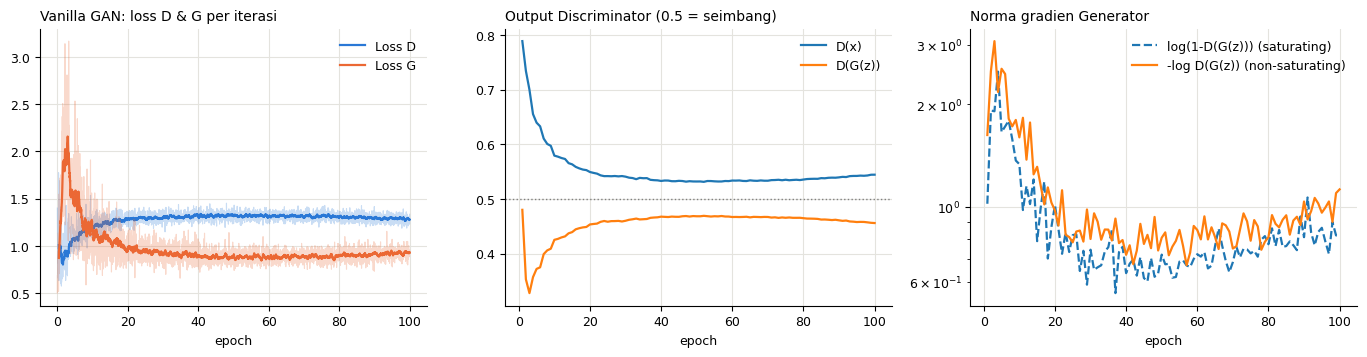

In [7]:
def moving_avg(v, k=20):
    v = np.asarray(v, float)
    return v if len(v) < k else np.convolve(v, np.ones(k) / k, mode="valid")

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
per_ep = len(history["iter_d_loss"]) / len(history["epoch"])
for key, col, lab in [("iter_d_loss", "#2a78d6", "Loss D"), ("iter_g_loss", "#eb6834", "Loss G")]:
    v = np.asarray(history[key]); xs = np.arange(len(v)) / per_ep
    axes[0].plot(xs, v, color=col, alpha=0.25, lw=0.8)
    m = moving_avg(v); axes[0].plot(xs[len(xs) - len(m):], m, color=col, label=lab)
axes[0].set_title("Vanilla GAN: loss D & G per iterasi", loc="left"); axes[0].set_xlabel("epoch"); axes[0].legend()

ep = history["epoch"]
axes[1].plot(ep, [e["D_x"] for e in history["train"]], label="D(x)")
axes[1].plot(ep, [e["D_G_z"] for e in history["train"]], label="D(G(z))")
axes[1].axhline(0.5, color="gray", ls=":", lw=1)
axes[1].set_title("Output Discriminator (0.5 = seimbang)", loc="left"); axes[1].set_xlabel("epoch"); axes[1].legend()

axes[2].plot(ep, [d["saturating"] for d in history["grad_diag"]], "--", label="log(1-D(G(z))) (saturating)")
axes[2].plot(ep, [d["non_saturating"] for d in history["grad_diag"]], label="-log D(G(z)) (non-saturating)")
axes[2].set_yscale("log"); axes[2].set_title("Norma gradien Generator", loc="left"); axes[2].set_xlabel("epoch"); axes[2].legend()
plt.show()

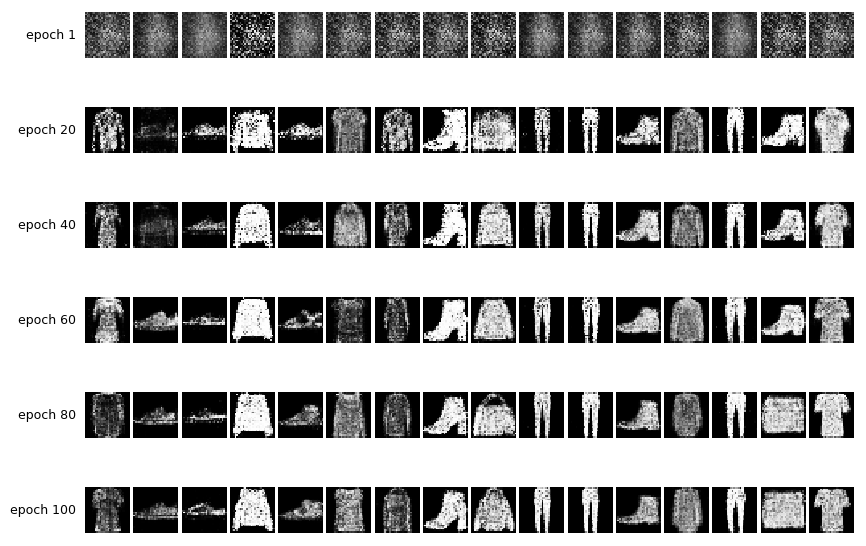

In [8]:
# Snapshot gambar dari z yang SAMA di beberapa epoch -> apakah keragamannya menyusut (mode collapse)?
snaps = history["snapshots"]
fig, axes = plt.subplots(len(snaps), 1, figsize=(10, 1.2 * len(snaps)))
for ax, (ep_k, arr) in zip(np.atleast_1d(axes), snaps.items()):
    show_imgs(ax, torch.tensor(arr), label=f"epoch {ep_k}")
plt.show()

## 7. Evaluasi: Sampling, FID, Mode Coverage, Latency

GAN tidak punya encoder, jadi **MSE/PSNR/SSIM tidak berlaku** (ditulis *N/A (Tanpa Encoder)*). Model dinilai dari sampel yang dihasilkan dari z ~ N(0, I).

FID           : 106.81312574662451
Mode coverage : {'class_hist': [0.13019999861717224, 0.09740000218153, 0.10000000149011612, 0.11180000007152557, 0.10999999940395355, 0.07400000095367432, 0.10320000350475311, 0.094200000166893, 0.09319999814033508, 0.0860000029206276], 'entropy_norm': 0.9954161047935486, 'modes_covered': 10}
Latency       : 0.41 ms / batch 64 | 0.32 ms / 1 sampel
Kestabilan    : {'g_loss_cv_last_half': 0.06101122081545039, 'd_loss_cv_last_half': 0.028623856080500738, 'final_D_x': 0.5443276773168616, 'final_D_G_z': 0.45594561610319845, 'label': 'Cukup stabil'}


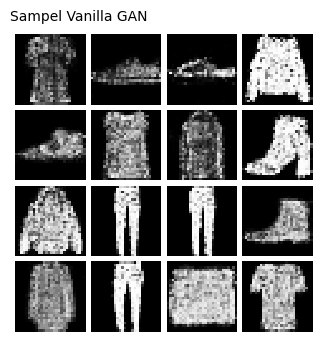

In [9]:
G.eval()
clf = load_mlp_classifier()
gen = lambda n, gen_=None: to_01(G(torch.randn(n, Z_DIM, device=device, generator=gen_)))

g = torch.Generator(device=device).manual_seed(SEED)
with torch.no_grad():
    samples = torch.cat([gen(min(500, FID_NUM_SAMPLES - i), g).cpu() for i in range(0, FID_NUM_SAMPLES, 500)])

metrics = {"model": "gan", "params": history["params"], "latent_dim": Z_DIM,
           "train_time_per_epoch_s": float(np.mean(history["epoch_time_s"]))}
metrics["fid"] = compute_fid(samples, splits)
metrics["mode_coverage"] = mode_coverage(samples, clf)
metrics["latency_ms_batch64"], metrics["latency_ms_batch64_std"] = measure_latency(lambda: gen(LATENCY_BATCH))
metrics["latency_ms_batch1"], metrics["latency_ms_batch1_std"] = measure_latency(lambda: gen(1))
metrics["latency_mode"] = "sampling satu langkah (single-pass)"
metrics["stability"] = stability_summary(history)
metrics["hparams"] = {"epochs": len(history["epoch"]), "lr": LEARNING_RATE, "betas": list(BETAS),
                      "batch_size": BATCH_SIZE, "z_dim": Z_DIM}

print(f"FID           : {metrics['fid']}")
print(f"Mode coverage : {metrics['mode_coverage']}")
print(f"Latency       : {metrics['latency_ms_batch64']:.2f} ms / batch 64 | {metrics['latency_ms_batch1']:.2f} ms / 1 sampel")
print(f"Kestabilan    : {metrics['stability']}")
fig, ax = plt.subplots(figsize=(4, 4)); show_imgs(ax, samples[:16], nrow=4, title="Sampel Vanilla GAN"); plt.show()

## 8. Interpolasi Laten (Figur 4 & Q4)

GAN tidak punya encoder. Jadi z_A dan z_B dipilih dari 2.000 z acak: z yang gambarnya **paling yakin** dikenali MLP Classifier sebagai kelas A dan kelas B.

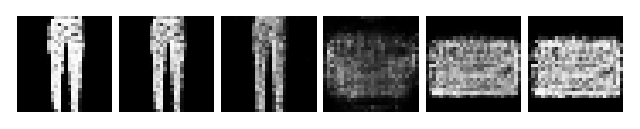

In [10]:
a, b = INTERP_CLASSES
g = torch.Generator(device=device).manual_seed(SEED)
with torch.no_grad():
    zc = torch.randn(2000, Z_DIM, device=device, generator=g)
    if clf is not None:
        pr = F.softmax(clf(to_01(G(zc))), 1)
        za, zb = zc[pr[:, a].argmax()][None], zc[pr[:, b].argmax()][None]
    else:
        za, zb = zc[:1], zc[1:2]
interp_imgs, interp_rows = interpolation_record("gan", za, zb, lambda z: to_01(G(z)), clf)
fig, ax = plt.subplots(figsize=(8, 1.6)); show_imgs(ax, interp_imgs); plt.show()

## 9. Simpan Hasil untuk Laporan

In [11]:
save_results("gan", metrics,
             artifacts={"samples16": samples[:16], "interp_imgs": interp_imgs, "interp_rows": interp_rows},
             history=history)

Hasil 'gan' tersimpan di c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results/
